# 03 — Simple Linear Regression

**Question:** If we use only the passage of time as an input, can a straight line describe the overall monthly passenger trend?

To avoid mixing training and evaluation, fit on the 12 monthly totals from 2025, then hold out all available 2026 months. This is a simple teaching model, not the final seasonal forecast.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(Path("data/processed/air_passenger_monthly.csv"), parse_dates=["DATE"])
series = df.groupby("DATE", as_index=False).PASSENGERS.sum().sort_values("DATE")
series["TIME_INDEX"] = np.arange(len(series))
train = series[series.DATE.dt.year.eq(2025)]
test = series[series.DATE.dt.year.eq(2026)]
X_train, y_train = train[["TIME_INDEX"]], train.PASSENGERS
X_test, y_test = test[["TIME_INDEX"]], test.PASSENGERS
print("Training months:", len(train), "| holdout months:", len(test))

Training months: 12 | holdout months: 7


## Fit the line and measure holdout error
MAE is the average absolute error in passenger counts. RMSE penalizes larger misses more strongly. R² on a short future holdout can be negative; that means this simple line is worse than predicting the holdout average.

In [2]:
model = LinearRegression().fit(X_train, y_train)
test = test.copy()
test["PREDICTION"] = model.predict(X_test)
mae = mean_absolute_error(y_test, test.PREDICTION)
rmse = mean_squared_error(y_test, test.PREDICTION) ** 0.5
r2 = r2_score(y_test, test.PREDICTION)
print(f"Slope: {model.coef_[0]:,.0f} passenger records per month index")
print(f"MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | R²: {r2:.3f}")
display(test[["DATE", "PASSENGERS", "PREDICTION"]])

Slope: 721,405 passenger records per month index
MAE: 8,151,246 | RMSE: 10,787,777 | R²: -0.585
         DATE   PASSENGERS    PREDICTION
12 2026-01-01   79645464.0  9.660178e+07
13 2026-02-01   76884283.0  9.732319e+07
14 2026-03-01   93999761.0  9.804459e+07
15 2026-04-01   90450847.0  9.876600e+07
16 2026-05-01   95323217.0  9.948740e+07
17 2026-06-01   97745648.0  1.002088e+08
18 2026-07-01  101606380.0  1.009302e+08


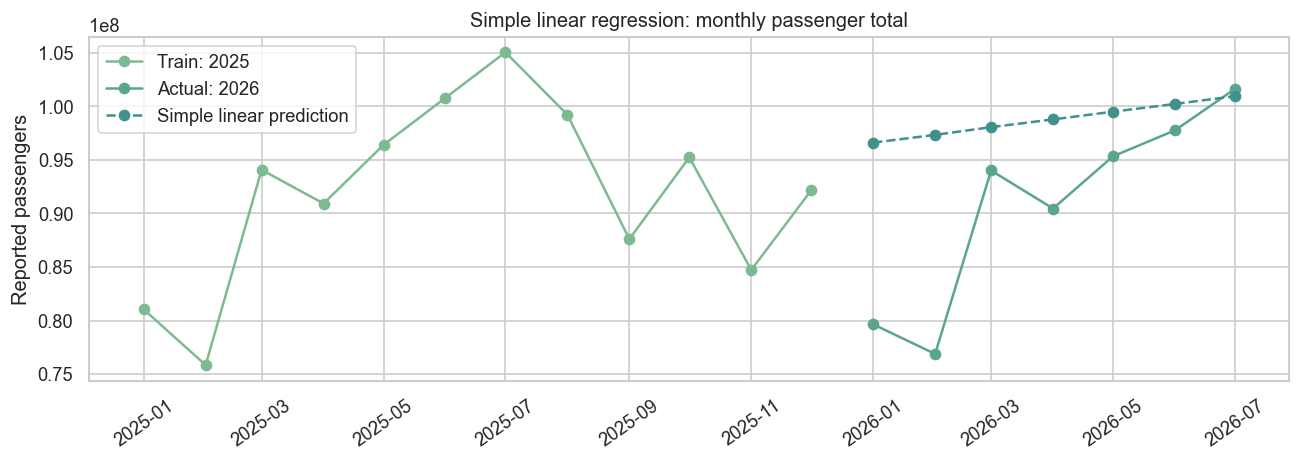

In [3]:
plt.figure(figsize=(11, 4))
plt.plot(train.DATE, train.PASSENGERS, marker="o", label="Train: 2025")
plt.plot(test.DATE, test.PASSENGERS, marker="o", label="Actual: 2026")
plt.plot(test.DATE, test.PREDICTION, marker="o", linestyle="--", label="Simple linear prediction")
plt.title("Simple linear regression: monthly passenger total")
plt.ylabel("Reported passengers")
plt.xlabel("")
plt.legend()
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Interpretation
This model has just one feature: month order. It cannot represent recurring summer/winter changes, airline mix, or route differences. Compare its holdout error with the polynomial, multiple regression, and seasonal baseline results in Notebook 07.
